In [1]:
from pathlib import Path
from typing import Dict

import pandas as pd

# Pandas options
pd.options.display.max_rows = 30
pd.options.display.max_columns = 30

In [2]:
def load_worldbank_datasets(
    folder: str | Path,
    melt: bool = False,
    value_name: str = "value"
) -> Dict[str, pd.DataFrame]:
    """
    Read all World-Bank DS2 CSV files in *folder* and return a dict of DataFrames.

    Parameters
    ----------
    folder : str | Path
        Directory where the CSV files live.
    melt : bool, default False
        If True, each DataFrame is reshaped from wide (una colonna per anno)
        to long (una riga per anno) with columns:
        ['Country Name', 'Country Code', 'Indicator Name',
         'Indicator Code', 'year', value_name].
    value_name : str, default 'value'
        Name for the melted value column.

    Returns
    -------
    Dict[str, pd.DataFrame]
        Keys are the *Indicator Code* (es. 'ST.INT.ARVL'),
        values are the corresponding cleaned DataFrames.
    """
    folder = Path(folder)
    dataframes: Dict[str, pd.DataFrame] = {}

    # scorriamo tutti i .csv (gli 0X_API_XYZ.csv caricati)
    for csv_path in sorted(folder.glob("*.csv")):
        # Estraggo il codice indicatore dal nome file: ..._API_<CODE>_...
        try:
            indicator_code = csv_path.stem.split("_API_")[1].split("_")[0]
        except IndexError:              # in caso di nome non previsto
            indicator_code = csv_path.stem

        # 1. Caricamento
        df = pd.read_csv(csv_path)

        # 2. Pulizia: rimuovo eventuali colonne 'Unnamed'
        df = df.loc[:, ~df.columns.str.contains(r"^Unnamed")]

        # 3. Convertiamo gli anni (1960…2024) da str a int per sicurezza
        year_cols = df.columns[4:]      # prime 4 colonne sono meta-info
        df[year_cols] = df[year_cols].apply(pd.to_numeric, errors="coerce")

        # 4. Optionally reshape wide → long
        if melt:
            df = df.melt(
                id_vars=df.columns[:4],
                var_name="year",
                value_name=value_name
            )
            df["year"] = df["year"].astype("int16")

        dataframes[indicator_code] = df

    return dataframes


In [3]:
# Path alla cartella che contiene i file 00_API_*, 01_API_* …
DATA_DIR = Path("C:/Users/steno/pythonProjects/MasterS2I_pythonProject/all_data")   # oppure 'data/' se li sposti altrove

datasets = load_worldbank_datasets(DATA_DIR, melt=False)  # wide
# oppure: datasets = load_worldbank_datasets(DATA_DIR, melt=True)  # long

list_dataset_uploaded = list(datasets.keys())

list_dataset_uploaded

['ST.INT.ARVL',
 'ST.INT.DPRT',
 'ST.INT.RCPT.CD',
 'ST.INT.RCPT.XP.ZS',
 'ST.INT.TRNR.CD',
 'ST.INT.TRNX.CD',
 'ST.INT.TVLR.CD',
 'ST.INT.XPND.CD',
 'ST.INT.XPND.MP.ZS']

In [4]:
# Accesso ai singoli dataset
arrivals_df      = datasets["ST.INT.ARVL"]   # Arrivi turistici (n. persone)
departures_df    = datasets["ST.INT.DPRT"]  # Partenze residenti
receipts_usd_df  = datasets["ST.INT.RCPT.CD"]   # Ricavi turismo (US$ correnti)
receipts_per_df  = datasets["ST.INT.RCPT.XP.ZS"]  # Ricavi turismo % export
trnr_cd_df       = datasets["ST.INT.TRNR.CD"]   # Dettaglio ricavi trasporto / travel
trnx_cd_df       = datasets["ST.INT.TRNX.CD"]  # Dettaglio ricavi trasporto / travel
tvlr_cd_df       = datasets["ST.INT.TVLR.CD"]   # Dettaglio ricavi trasporto / travel
xpnd_cd_df       = datasets["ST.INT.XPND.CD"]  # Spesa outbound
xpnd_mp_df       = datasets["ST.INT.XPND.MP.ZS"]   # Spesa outbound

In [5]:
for name, df in datasets.items():
    print(f"\n>>> {name}")
    print(df.columns.tolist())


>>> ST.INT.ARVL
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']

>>> ST.INT.DPRT
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '199

In [6]:
# -*- coding: utf-8 -*-
import pandas as pd

# --- Parametri di utilità ---------------------------------------------
YEARS = [str(y) for y in range(1995, 2021)]   # anni che ti interessano
# ----------------------------------------------------------------------

for name, df in datasets.items():
    print(f"\n{'='*70}\n>>> {name}  |  shape={df.shape}\n{'-'*70}")
    
    # 1) Info: schema, dtypes, nulls e memoria occupata
    df.info(memory_usage="deep")
    
    # 2) Describe: statistiche solo sulle colonne numeriche (anni)
    #    Se qualche anno fosse assente in questo dataset, Pandas lo ignorerà.
    print("\nStatistiche descrittive (1995-2020):")
    display(                       # Jupyter visualizza in tabella
        df.loc[:, YEARS].describe().transpose()  # .T per leggibilità
    )


>>> ST.INT.ARVL  |  shape=(266, 69)
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 69 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            0 non-null      float64
 15  1971            0

,count,mean,std,min,25%,50%,75%,max
1995,207.0,4.120028e+07,1.370355e+08,899.999976,2.195000e+05,1.433000e+06,8.349622e+06,1.082522e+09
1996,214.0,4.287684e+07,1.424116e+08,699.999988,2.602500e+05,1.355000e+06,8.924200e+06,1.143489e+09
1997,215.0,4.476619e+07,1.484371e+08,1000.000000,3.020000e+05,1.336000e+06,9.662688e+06,1.193996e+09
1998,215.0,4.467830e+07,1.503143e+08,1000.000000,2.900000e+05,1.339000e+06,9.617975e+06,1.209957e+09
1999,215.0,4.639856e+07,1.548656e+08,1100.000024,3.240000e+05,1.431000e+06,9.648000e+06,1.254467e+09
2000,217.0,4.880781e+07,1.629260e+08,1100.000024,3.160000e+05,1.683000e+06,1.042800e+07,1.332379e+09
2001,219.0,4.703305e+07,1.566044e+08,1100.000024,3.315000e+05,1.753000e+06,1.113719e+07,1.299005e+09
2002,216.0,4.844417e+07,1.591249e+08,1299.999952,3.707500e+05,1.892500e+06,1.155925e+07,1.319582e+09
2003,220.0,4.717230e+07,1.560821e+08,1399.999976,3.967500e+05,1.906500e+06,1.197180e+07,1.300067e+09
2004,220.0,5.590063e+07,1.730134e+08,1299.999952,4.625000e+05,2.170000e+06,1.848911e+07,1.436450e+09



>>> ST.INT.DPRT  |  shape=(266, 69)
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 69 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            0 non-null      float64
 15  1971            0

,count,mean,std,min,25%,50%,75%,max
1995,89.0,2.925840e+07,6.532073e+07,3000.000000,228000.0,1237000.0,1.308300e+07,3.165019e+08
1996,89.0,2.991042e+07,6.570817e+07,3000.000000,275000.0,1428000.0,1.226000e+07,3.226086e+08
1997,98.0,5.424466e+07,1.311842e+08,6000.000000,355000.0,1903500.0,3.668825e+07,9.300660e+08
1998,103.0,6.497170e+07,1.507993e+08,1899.999976,342000.0,1961000.0,4.846100e+07,9.821260e+08
1999,103.0,6.907904e+07,1.601461e+08,2200.000048,368000.0,2271000.0,5.351250e+07,1.043185e+09
2000,107.0,7.172601e+07,1.688081e+08,2900.000095,433500.0,2394000.0,5.065250e+07,1.122419e+09
2001,108.0,7.081965e+07,1.673285e+08,2700.000048,464500.0,2589500.0,4.598875e+07,1.121399e+09
2002,107.0,7.163712e+07,1.686316e+08,2700.000048,531000.0,2629000.0,4.485150e+07,1.127809e+09
2003,108.0,7.165835e+07,1.684302e+08,2599.999905,561750.0,3343500.0,4.063675e+07,1.130457e+09
2004,109.0,7.563560e+07,1.767127e+08,2299.999952,680000.0,3941000.0,4.204689e+07,1.201164e+09



>>> ST.INT.RCPT.CD  |  shape=(266, 69)
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 69 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            0 non-null      float64
 15  1971          

...

,count,mean,std,min,25%,50%,75%,max
1995,200.0,1.607682e+10,5.484134e+10,9.000000e+05,66500000.0,6.432789e+08,4.976942e+09,4.275696e+11
1996,203.0,1.728823e+10,5.839841e+10,1.200000e+06,79000000.0,6.730000e+08,5.462480e+09,4.627367e+11
1997,206.0,1.722746e+10,5.803663e+10,1.000000e+05,74250000.0,6.580000e+08,5.585421e+09,4.648966e+11
1998,206.0,1.731570e+10,5.899453e+10,4.000000e+05,98250000.0,7.170000e+08,5.771447e+09,4.669706e+11
1999,208.0,1.804721e+10,6.146831e+10,7.000000e+05,98500000.0,7.145000e+08,5.614008e+09,4.883849e+11
2000,209.0,1.843393e+10,6.206583e+10,8.000000e+05,97000000.0,7.130000e+08,5.677000e+09,4.988812e+11
2001,212.0,1.807412e+10,6.027860e+10,1.000000e+05,90500000.0,6.355000e+08,5.689501e+09,4.895722e+11
2002,216.0,1.864222e+10,6.216578e+10,7.000000e+05,108000000.0,7.635000e+08,5.996472e+09,5.087117e+11
2003,216.0,2.071714e+10,6.948098e+10,7.000000e+05,123500000.0,8.445000e+08,6.680646e+09,5.625661e+11
2004,219.0,2.434041e+10,8.103116e+10,1.000000e+06,170000000.0,9.050000e+08,7.940500e+09,6.657270e+11



>>> ST.INT.XPND.CD  |  shape=(266, 69)
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 69 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            0 non-null      float64
 15  1971          

,count,mean,std,min,25%,50%,75%,max
1995,140.0,1.829118e+10,7.214308e+10,5.800000e+06,6.725000e+07,2.730000e+08,3.036500e+09,5.010455e+11
1996,146.0,1.836362e+10,7.368788e+10,4.700000e+06,7.475000e+07,2.900000e+08,3.003637e+09,5.253324e+11
1997,151.0,1.753703e+10,7.175252e+10,3.500000e+06,7.200000e+07,3.170000e+08,2.963498e+09,5.243061e+11
1998,149.0,1.809859e+10,7.341528e+10,1.900000e+06,7.300000e+07,3.260000e+08,2.970423e+09,5.292108e+11
1999,153.0,1.921945e+10,7.541897e+10,1.000000e+05,1.000000e+08,3.850000e+08,3.065167e+09,5.352794e+11
2000,162.0,2.104698e+10,7.541135e+10,2.000000e+05,1.227500e+08,4.015000e+08,3.721250e+09,5.512737e+11
2001,170.0,1.999528e+10,7.156772e+10,3.000000e+05,1.125000e+08,4.240000e+08,4.322750e+09,5.381974e+11
2002,177.0,2.051161e+10,7.309181e+10,3.000000e+05,1.150000e+08,5.040000e+08,4.350000e+09,5.595324e+11
2003,185.0,2.203620e+10,8.001491e+10,3.000000e+05,1.290000e+08,5.070000e+08,4.385000e+09,6.149509e+11
2004,186.0,2.519108e+10,9.150916e+10,4.000000e+05,1.442500e+08,5.740000e+08,5.239750e+09,7.118906e+11



>>> ST.INT.XPND.MP.ZS  |  shape=(266, 69)
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 69 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1960            0 non-null      float64
 5   1961            0 non-null      float64
 6   1962            0 non-null      float64
 7   1963            0 non-null      float64
 8   1964            0 non-null      float64
 9   1965            0 non-null      float64
 10  1966            0 non-null      float64
 11  1967            0 non-null      float64
 12  1968            0 non-null      float64
 13  1969            0 non-null      float64
 14  1970            0 non-null      float64
 15  1971       

,count,mean,std,min,25%,50%,75%,max
1995,142.0,6.942303,3.604930,1.073477,4.645443,6.780418,8.118730,23.475082
1996,151.0,7.014327,4.061018,0.678355,4.701917,6.851474,8.389471,37.339760
1997,162.0,7.034329,4.276669,1.116094,4.698813,6.764188,8.286642,42.440927
1998,160.0,7.134810,4.261891,0.909304,4.944069,6.810742,8.297912,41.687252
1999,162.0,7.061813,3.315041,1.062168,5.350546,6.578192,8.488266,23.547298
2000,167.0,6.984541,3.352546,1.219233,5.128048,6.133140,8.198094,25.078272
2001,172.0,7.191854,3.626310,0.758741,5.450986,6.301415,8.146881,25.859181
2002,180.0,7.496202,3.804211,0.734244,5.457870,6.508049,8.648031,24.449576
2003,188.0,7.349502,4.031957,0.556739,4.912435,6.570467,8.336056,24.967664
2004,186.0,6.998696,3.832751,0.808688,4.687867,6.339944,7.877072,23.126809


##### C'è qualcosa in comune in questi dati:
- Non abbiamo valori tra il 1960 e il 1994
- Non abbiamo valori tra il 2021 e il 2024

##### Posso, quindi, rimuovere tutte queste colonne

In [7]:
# --- Trim yearly columns to 1995-2020 ---------------------------------
from typing import List, Dict
import pandas as pd

def trim_year_columns(dataframes: Dict[str, pd.DataFrame],
                      start_year: int = 1995,
                      end_year: int = 2020) -> None:
    """
    Remove year columns earlier than `start_year` from every DataFrame
    in the provided dictionary. Operates in-place.

    Parameters
    ----------
    dataframes : dict[str, pd.DataFrame]
        Dict of World Bank indicator DataFrames.
    start_year : int, default 1995
        First year to keep.
    end_year : int, default 2020
        Last year to keep (inclusive). Set None to keep all remaining years.
    """
    meta_cols: List[str] = [
        "Country Name", "Country Code",
        "Indicator Name", "Indicator Code"
    ]

    for name, df in dataframes.items():
        # Identify numeric year columns to keep
        year_cols = [
            col for col in df.columns
            if col.isdigit() and int(col) >= start_year
               and (end_year is None or int(col) <= end_year)
        ]

        # Re-order: metadata first, then years
        keep_cols = [c for c in meta_cols if c in df.columns] + year_cols
        dataframes[name] = df.loc[:, keep_cols]

        print(f"{name}: kept {len(year_cols)} year cols "
              f"({year_cols[0] if year_cols else '-'}-{year_cols[-1] if year_cols else '-'})")

# --- Execute -----------------------------------------------------------
trim_year_columns(datasets, start_year=1995, end_year=2020)


ST.INT.ARVL: kept 26 year cols (1995-2020)
ST.INT.DPRT: kept 26 year cols (1995-2020)
ST.INT.RCPT.CD: kept 26 year cols (1995-2020)
ST.INT.RCPT.XP.ZS: kept 26 year cols (1995-2020)
ST.INT.TRNR.CD: kept 26 year cols (1995-2020)
ST.INT.TRNX.CD: kept 26 year cols (1995-2020)
ST.INT.TVLR.CD: kept 26 year cols (1995-2020)
ST.INT.XPND.CD: kept 26 year cols (1995-2020)
ST.INT.XPND.MP.ZS: kept 26 year cols (1995-2020)


In [8]:
for name, df in datasets.items():
    print(f"\n>>> {name}")
    print(df.columns.tolist())


>>> ST.INT.ARVL
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020']

>>> ST.INT.DPRT
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020']

>>> ST.INT.RCPT.CD
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020']

>>> ST.INT.RCPT.XP.ZS
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1995', '1996', '1997',

In [9]:
for name, df in datasets.items():
    print(f"\n{'='*70}\n>>> {name}  |  shape={df.shape}\n{'-'*70}")
    
    # 1) Info: schema, dtypes, nulls e memoria occupata
    df.info(memory_usage="deep")


>>> ST.INT.ARVL  |  shape=(266, 30)
----------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 30 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    266 non-null    object 
 1   Country Code    266 non-null    object 
 2   Indicator Name  266 non-null    object 
 3   Indicator Code  266 non-null    object 
 4   1995            207 non-null    float64
 5   1996            214 non-null    float64
 6   1997            215 non-null    float64
 7   1998            215 non-null    float64
 8   1999            215 non-null    float64
 9   2000            217 non-null    float64
 10  2001            219 non-null    float64
 11  2002            216 non-null    float64
 12  2003            220 non-null    float64
 13  2004            220 non-null    float64
 14  2005            225 non-null    float64
 15  2006            2

In [10]:
from functools import reduce

META_COLS = ["Country Name", "Country Code"]
YEARS = [str(y) for y in range(1995, 2021)]

def wide_to_long(df: pd.DataFrame, value_name: str) -> pd.DataFrame:
    """Convert World Bank wide→long, keeping only 1995-2020."""
    long_df = (
        df.melt(id_vars=META_COLS,
                value_vars=YEARS,
                var_name="Year",
                value_name=value_name)
          .dropna(subset=[value_name])          # opzionale
    )
    long_df["Year"] = long_df["Year"].astype(int)
    return long_df.reset_index(drop=True)

# ---- 1) Costruisci i long-frame --------------------------------------
df_map = {
    "Arrivals":   arrivals_df,
    "Departures": departures_df,
    "ReceiptsUSD": receipts_usd_df,
    "ReceiptsEXP": receipts_per_df,
    "TrnR": trnr_cd_df,
    "TrnX": trnx_cd_df,
    "TvlR": tvlr_cd_df,
    "SpendUSD": xpnd_cd_df,
    "SpendEXP": xpnd_mp_df,
}

long_frames = [wide_to_long(df, name) for name, df in df_map.items()]

# ---- 2) Merge progressivo (outer join) -------------------------------
for lf in long_frames:
    lf.sort_values(["Country Code", "Year"], inplace=True)

merged_long_df = reduce(
    lambda left, right: pd.merge(
        left, right,
        on=["Country Code", "Year", "Country Name"],
        how="outer"
    ),
    long_frames
)

print("Shape finale:", merged_long_df.shape)

Shape finale: (6382, 12)


In [11]:
merged_long_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6382 entries, 0 to 6381
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  6382 non-null   object 
 1   Country Code  6382 non-null   object 
 2   Year          6382 non-null   int32  
 3   Arrivals      5800 non-null   float64
 4   Departures    2968 non-null   float64
 5   ReceiptsUSD   4965 non-null   float64
 6   ReceiptsEXP   4729 non-null   float64
 7   TrnR          4228 non-null   float64
 8   TrnX          4380 non-null   float64
 9   TvlR          5683 non-null   float64
 10  SpendUSD      4810 non-null   float64
 11  SpendEXP      4789 non-null   float64
dtypes: float64(9), int32(1), object(2)
memory usage: 573.5+ KB


In [12]:
merged_long_df.head(30)

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
0,Aruba,ABW,1995,9.120000e+05,NaN,5.540000e+08,27.806410,3.300000e+07,6.000000e+06,5.210000e+08,7.900000e+07,3.914897
1,Aruba,ABW,1996,9.570000e+05,NaN,6.660000e+08,26.580602,4.600000e+07,8.000000e+06,6.200000e+08,1.280000e+08,5.001528
2,Aruba,ABW,1997,9.470000e+05,NaN,7.260000e+08,28.533099,3.700000e+07,5.000000e+06,6.890000e+08,1.610000e+08,5.936676
3,Aruba,ABW,1998,9.060000e+05,NaN,7.860000e+08,38.213374,4.500000e+07,5.000000e+06,7.410000e+08,1.400000e+08,6.759272
4,Aruba,ABW,1999,9.720000e+05,NaN,7.820000e+08,62.542949,5.300000e+07,1.100000e+07,7.290000e+08,1.510000e+08,9.495387
5,Aruba,ABW,2000,1.211000e+06,NaN,8.500000e+08,46.815961,3.600000e+07,1.700000e+07,8.140000e+08,1.630000e+08,10.824497
6,Aruba,ABW,2001,1.178000e+06,NaN,8.250000e+08,40.877874,3.000000e+06,2.100000e+07,8.220000e+08,1.560000e+08,9.825233
7,Aruba,ABW,2002,1.225000e+06,NaN,8.350000e+08,57.634615,1.000000e+06,1.300000e+07,8.340000e+08,1.720000e+08,10.841341
8,Aruba,ABW,2003,1.184000e+06,NaN,8.581000e+08,48.586190,1.000000e+05,2.500000e+07,8.580000e+08,2.130000e+08,11.895988
9,Aruba,ABW,2004,1.304000e+06,NaN,1.057000e+09,22.547412,NaN,3.000000e+07,1.057000e+09,2.480000e+08,5.856828


In [13]:
# ---------------------------------------------------------------------
# 1. Quante righe, quanti Paesi distinti, quanti NaN?
# ---------------------------------------------------------------------
print(f"Rows total         : {len(merged_long_df):,}")
print(f"Unique Country Code: {merged_long_df['Country Code'].nunique():,}")
print(f"Unique Country Name: {merged_long_df['Country Name'].nunique():,}")
print("\nNaN check:")
print(merged_long_df[['Country Code', 'Country Name']].isna().sum())

# ---------------------------------------------------------------------
# 2. Quante righe per Paese (value_counts sul Nome) --------------------
country_counts = (
    merged_long_df['Country Name']
    .value_counts(dropna=True)         # dropna=True ‒ escludiamo eventuali NaN
    .to_frame('row_count')
)

display(country_counts.head(20))       # prime 20 per ispezione visiva
# Se non sei in Jupyter, usa print(country_counts.head(20))

# ---------------------------------------------------------------------
# 3. Incoerenze Nome ⇆ Codice -----------------------------------------
# (a) un codice che appare con più nomi
dup_code = (
    merged_long_df
      .dropna(subset=['Country Code', 'Country Name'])
      .drop_duplicates(subset=['Country Code', 'Country Name'])
      .groupby('Country Code')['Country Name']
      .nunique()
      .loc[lambda s: s > 1]
      .sort_values(ascending=False)
)

# (b) un nome che appare con più codici
dup_name = (
    merged_long_df
      .dropna(subset=['Country Code', 'Country Name'])
      .drop_duplicates(subset=['Country Code', 'Country Name'])
      .groupby('Country Name')['Country Code']
      .nunique()
      .loc[lambda s: s > 1]
      .sort_values(ascending=False)
)

print("\nCodici ISO con >1 nome:")
display(dup_code.to_frame('n_names'))
print("\nNomi Paese con >1 codice:")
display(dup_name.to_frame('n_codes'))

# ---------------------------------------------------------------------
# 4. (opzionale) Elenco dei record problematici per revisione manuale --
problematic = merged_long_df[
    merged_long_df['Country Code'].isin(dup_code.index) |
    merged_long_df['Country Name'].isin(dup_name.index)
][['Country Code', 'Country Name']].drop_duplicates()

display(problematic.sort_values(['Country Code', 'Country Name']).head(50))

Rows total         : 6,382
Unique Country Code: 256
Unique Country Name: 256

NaN check:
Country Code    0
Country Name    0
dtype: int64


,row_count
Country Name,
Aruba,26
Indonesia,26
Morocco,26
Monaco,26
Moldova,26
Madagascar,26
Maldives,26
Mexico,26
North Macedonia,26



Codici ISO con >1 nome:


,n_names
Country Code,



Nomi Paese con >1 codice:


,n_codes
Country Name,


,Country Code,Country Name


In [14]:
miss_by_metric = merged_long_df.isna().mean().sort_values()
print(miss_by_metric)

Country Name    0.000000
Country Code    0.000000
Year            0.000000
Arrivals        0.091194
TvlR            0.109527
ReceiptsUSD     0.222031
SpendUSD        0.246318
SpendEXP        0.249608
ReceiptsEXP     0.259010
TrnX            0.313695
TrnR            0.337512
Departures      0.534942
dtype: float64


In [15]:
merged_long_df[merged_long_df["Country Name"]=="Congo, Rep."] # CORREGGERE ORDINE!

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
971,"Congo, Rep.",COG,2010,199000.0,NaN,3.900000e+07,0.432836,1.200000e+07,101000000.0,27000000.0,312000000.0,4.272696
972,"Congo, Rep.",COG,2011,224000.0,NaN,4.700000e+07,0.407837,9.000000e+06,104000000.0,38000000.0,327000000.0,4.096723
973,"Congo, Rep.",COG,2012,259000.0,161000.0,6.800000e+07,0.661710,5.000000e+06,135000000.0,63000000.0,308000000.0,4.422520
974,"Congo, Rep.",COG,2013,345000.0,180000.0,5.240000e+07,0.551212,4.000000e+05,156000000.0,52000000.0,360000000.0,5.002908
975,"Congo, Rep.",COG,2014,229000.0,NaN,5.690000e+07,0.597615,1.900000e+06,178000000.0,55000000.0,435000000.0,4.753933
976,"Congo, Rep.",COG,2015,224000.0,NaN,4.690000e+07,0.923139,9.000000e+05,233000000.0,46000000.0,557000000.0,5.858163
977,"Congo, Rep.",COG,2016,213000.0,NaN,4.290000e+07,0.932706,1.900000e+06,206000000.0,41000000.0,457000000.0,6.267988
978,"Congo, Rep.",COG,2017,151000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
979,"Congo, Rep.",COG,2018,158000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5987,"Congo, Rep.",COG,1995,NaN,NaN,1.466914e+07,1.067607,6.691400e+05,17000000.0,14000000.0,69000000.0,5.126833


In [16]:
merged_long_df[merged_long_df["Country Name"]=="Italy"] # CORREGGERE ORDINE!

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
2506,Italy,ITA,1995,5.570600e+07,NaN,3.041100e+10,10.481021,1.694000e+09,2.390000e+09,2.871700e+10,1.720100e+10,7.025774
2507,Italy,ITA,1996,5.980500e+07,NaN,3.188400e+10,10.216263,1.869000e+09,2.813000e+09,3.001500e+10,1.861900e+10,7.449522
2508,Italy,ITA,1997,5.799800e+07,4.019600e+07,3.141500e+10,10.420362,1.701000e+09,3.033000e+09,2.971400e+10,1.967600e+10,7.750797
2509,Italy,ITA,1998,5.849900e+07,4.243100e+07,3.133900e+10,10.254242,1.525000e+09,2.941000e+09,2.981400e+10,2.053900e+10,7.729190
2510,Italy,ITA,1999,5.952100e+07,4.239000e+07,2.957000e+10,10.188412,1.221000e+09,2.700000e+09,2.834900e+10,1.958700e+10,7.282819
2511,Italy,ITA,2000,6.270200e+07,4.462800e+07,2.871200e+10,9.792397,1.214000e+09,2.484000e+09,2.749800e+10,1.817000e+10,6.400732
2512,Italy,ITA,2001,6.096000e+07,4.361100e+07,2.692400e+10,8.993355,1.095000e+09,2.204000e+09,2.582900e+10,1.700200e+10,5.954308
2513,Italy,ITA,2002,6.356100e+07,4.466000e+07,2.821300e+10,9.052032,1.320000e+09,2.713000e+09,2.689300e+10,1.965200e+10,6.497131
2514,Italy,ITA,2003,6.302600e+07,4.635700e+07,3.262300e+10,8.868111,1.346000e+09,3.144000e+09,3.127700e+10,2.374800e+10,6.578497
2515,Italy,ITA,2004,5.848000e+07,4.040000e+07,3.789300e+10,8.741567,2.495000e+09,3.605000e+09,3.539800e+10,2.407600e+10,5.681115


In [17]:
# riordino i dati per codice paese e per anno!

merged_long_df = (
    merged_long_df
      .sort_values(["Country Code", "Year"], ascending=[True, True])
      .reset_index(drop=True)             # indice 0 … n-1, comodo per iterare
)

In [18]:
dupl = merged_long_df.duplicated(subset=["Country Code", "Year"])
print(f"Duplicati (stessa chiave): {dupl.sum()}")

Duplicati (stessa chiave): 0


In [19]:
merged_long_df

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
0,Aruba,ABW,1995,912000.0,NaN,554000000.0,27.806410,33000000.0,6000000.0,521000000.0,79000000.0,3.914897
1,Aruba,ABW,1996,957000.0,NaN,666000000.0,26.580602,46000000.0,8000000.0,620000000.0,128000000.0,5.001528
2,Aruba,ABW,1997,947000.0,NaN,726000000.0,28.533099,37000000.0,5000000.0,689000000.0,161000000.0,5.936676
3,Aruba,ABW,1998,906000.0,NaN,786000000.0,38.213374,45000000.0,5000000.0,741000000.0,140000000.0,6.759272
4,Aruba,ABW,1999,972000.0,NaN,782000000.0,62.542949,53000000.0,11000000.0,729000000.0,151000000.0,9.495387
...,...,...,...,...,...,...,...,...,...,...,...,...
6377,Zimbabwe,ZWE,2016,2168000.0,3192000.0,194000000.0,4.778703,17000000.0,79000000.0,177000000.0,406000000.0,6.559708
6378,Zimbabwe,ZWE,2017,2423000.0,2768000.0,158000000.0,3.405013,9000000.0,22000000.0,149000000.0,337000000.0,5.416872
6379,Zimbabwe,ZWE,2018,2580000.0,2288000.0,191000000.0,3.688565,9000000.0,21000000.0,182000000.0,269000000.0,3.519928
6380,Zimbabwe,ZWE,2019,2294000.0,3275000.0,285000000.0,5.411115,6000000.0,53000000.0,279000000.0,257000000.0,4.760583


In [20]:
merged_long_df[merged_long_df["Country Name"]=="Congo, Rep."]

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
1078,"Congo, Rep.",COG,1995,NaN,NaN,1.466914e+07,1.067607,6.691400e+05,17000000.0,14000000.0,69000000.0,5.126833
1079,"Congo, Rep.",COG,1996,NaN,NaN,1.101759e+07,0.630758,1.759350e+04,8000000.0,11000000.0,86000000.0,5.646100
1080,"Congo, Rep.",COG,1997,NaN,NaN,NaN,NaN,NaN,3000000.0,10000000.0,68000000.0,4.866482
1081,"Congo, Rep.",COG,1998,NaN,NaN,NaN,NaN,NaN,15000000.0,9000000.0,69000000.0,4.873381
1082,"Congo, Rep.",COG,1999,NaN,NaN,1.350000e+07,0.790980,5.000000e+05,8000000.0,13000000.0,71000000.0,5.101449
1083,"Congo, Rep.",COG,2000,NaN,NaN,1.240000e+07,0.470617,4.000000e+05,9000000.0,12000000.0,59000000.0,4.930711
1084,"Congo, Rep.",COG,2001,NaN,NaN,2.260000e+07,1.026784,6.000000e+05,17000000.0,22000000.0,82000000.0,5.342525
1085,"Congo, Rep.",COG,2002,NaN,NaN,2.560000e+07,1.038461,6.000000e+05,15000000.0,25000000.0,85000000.0,5.228631
1086,"Congo, Rep.",COG,2003,NaN,NaN,3.000000e+07,1.057435,1.000000e+06,40000000.0,29000000.0,118000000.0,6.898669
1087,"Congo, Rep.",COG,2004,NaN,NaN,2.310000e+07,0.635248,1.100000e+06,73000000.0,22000000.0,176000000.0,8.849303


# Exploratory Data Analysis

In [21]:
# -*- coding: utf-8 -*-
import pandas as pd

def overview(df: pd.DataFrame) -> None:
    """Print quick overview + NaN percentage."""
    print(f"Shape: {df.shape}")
    print("\n-- dtypes --")
    print(df.dtypes)
    print("\n-- %% NaN per colonna --")
    pct_na = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
    display(pct_na.to_frame("pct_NaN").transpose())

overview(merged_long_df)


Shape: (6382, 12)

-- dtypes --
Country Name     object
Country Code     object
Year              int32
Arrivals        float64
Departures      float64
ReceiptsUSD     float64
ReceiptsEXP     float64
TrnR            float64
TrnX            float64
TvlR            float64
SpendUSD        float64
SpendEXP        float64
dtype: object

-- %% NaN per colonna --


,Departures,TrnR,TrnX,ReceiptsEXP,SpendEXP,SpendUSD,ReceiptsUSD,TvlR,Arrivals,Country Name,Country Code,Year
pct_NaN,53.5,33.8,31.4,25.9,25.0,24.6,22.2,11.0,9.1,0.0,0.0,0.0


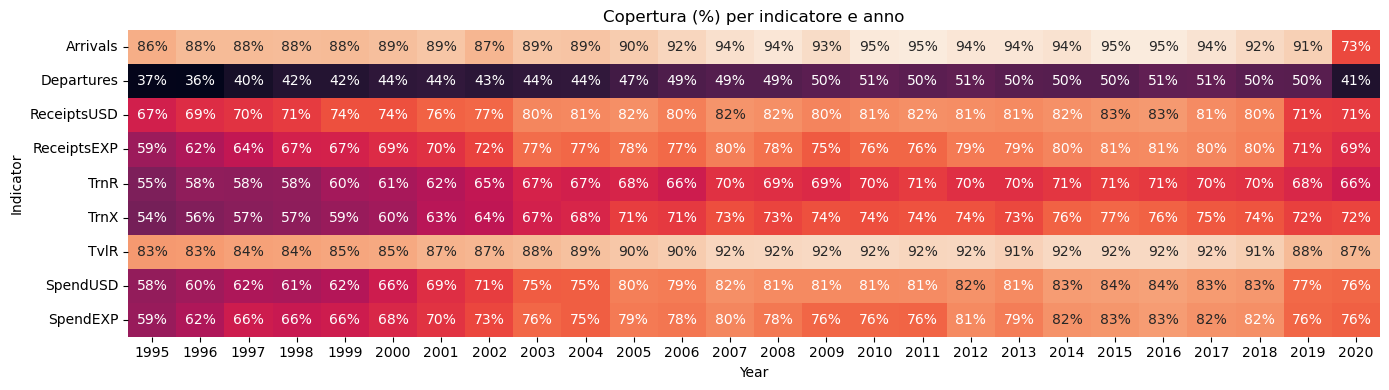

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

indicators = ["Arrivals", "Departures", "ReceiptsUSD", "ReceiptsEXP",
              "TrnR", "TrnX", "TvlR", "SpendUSD", "SpendEXP"]

coverage = (
    merged_long_df
      .groupby("Year")[indicators]
      .apply(lambda g: g.notna().mean())      # quota di Paesi con dato
      .T                                      # indicatori in righe
)

plt.figure(figsize=(14, 4))
sns.heatmap(coverage, annot=True, fmt=".0%", cbar=False)
plt.title("Copertura (%) per indicatore e anno")
plt.xlabel("Year")
plt.ylabel("Indicator")
plt.tight_layout()
plt.show()


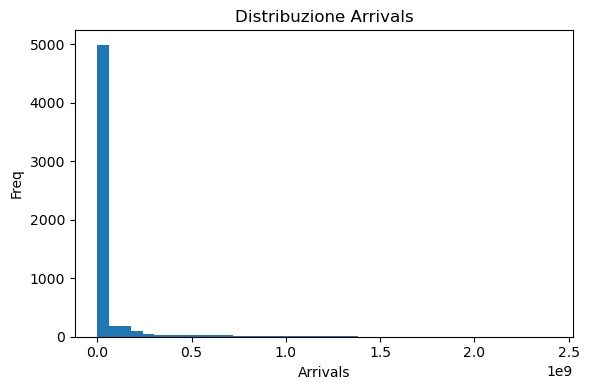

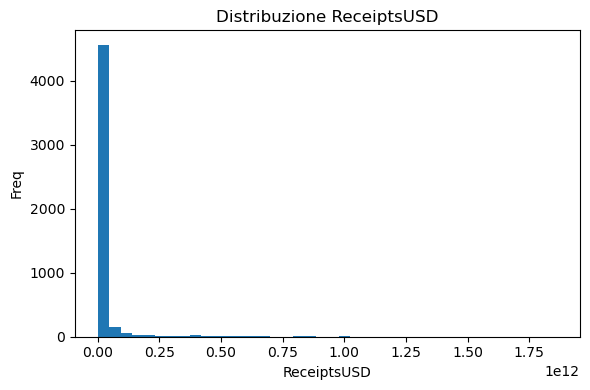

In [23]:
def plot_hist(df: pd.DataFrame, column: str, bins: int = 30) -> None:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(df[column].dropna(), bins=bins)
    ax.set_title(f"Distribuzione {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Freq")
    plt.tight_layout()
    plt.show()

plot_hist(merged_long_df, "Arrivals", bins=40)
plot_hist(merged_long_df, "ReceiptsUSD", bins=40)


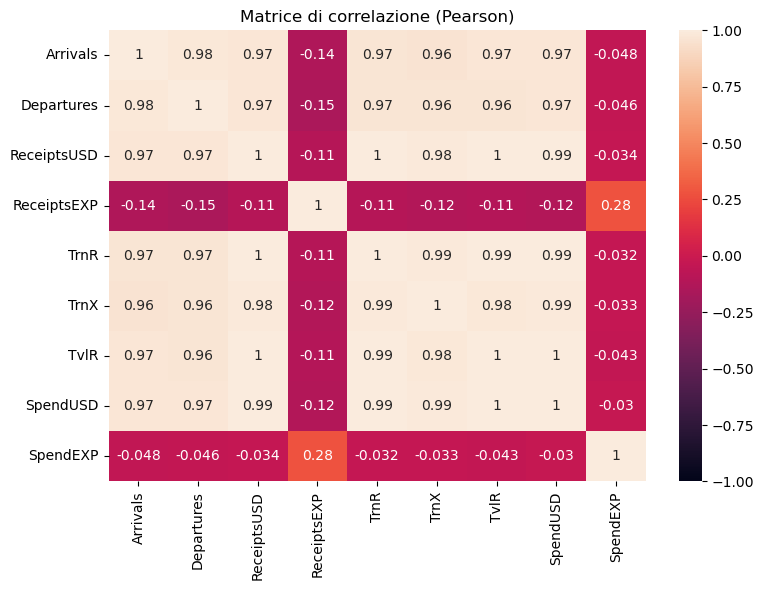

In [24]:
corr = merged_long_df[indicators].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, vmin=-1, vmax=1)
plt.title("Matrice di correlazione (Pearson)")
plt.tight_layout()
plt.show()

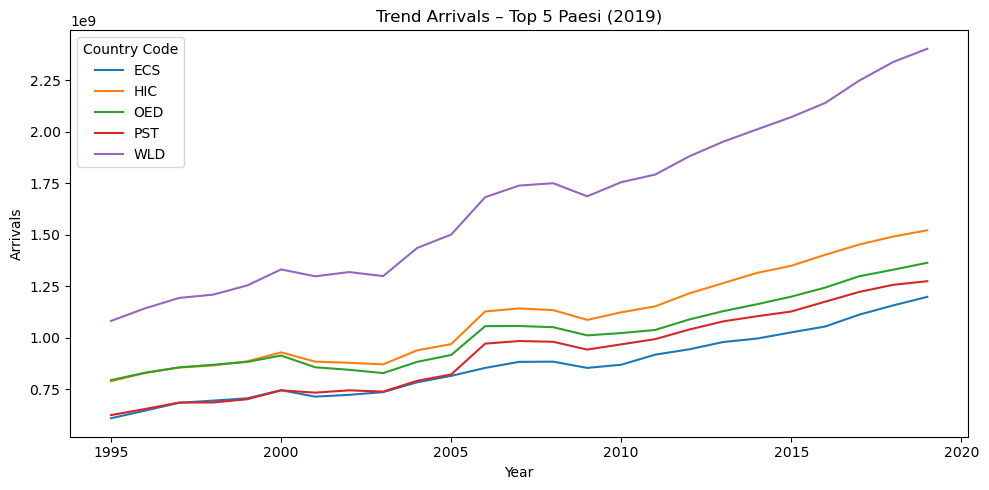

In [25]:
year_ref = 2019
top5 = (merged_long_df[merged_long_df["Year"] == year_ref]
        .nlargest(5, "Arrivals")["Country Code"])

trend = merged_long_df[merged_long_df["Country Code"].isin(top5)]

plt.figure(figsize=(10, 5))
for cc, grp in trend.groupby("Country Code"):
    plt.plot(grp["Year"], grp["Arrivals"], label=cc)

plt.title(f"Trend Arrivals – Top 5 Paesi ({year_ref})")
plt.xlabel("Year")
plt.ylabel("Arrivals")
plt.legend(title="Country Code")
plt.tight_layout()
plt.show()


##### C'è un problema. Ci sono codici paese che non si riferiscono effettivamente a un solo stato ma ad aggregati. Li isolo per effettuare meglio le analisi

In [26]:
# installiamo pycountry se serve
# !pip install -q pycountry               # scommenta in Jupyter o colpo singolo

import pandas as pd
import pycountry   # ISO-3166-1 reference

# Costruiamo l’insieme dei codici ISO ufficiali
iso_set = {c.alpha_3 for c in pycountry.countries}

# Creiamo la maschera boolean: True = aggregato/regione
mask_aggregate = ~merged_long_df["Country Code"].isin(iso_set)

# Split del DataFrame
df_countries  = merged_long_df[~mask_aggregate].reset_index(drop=True)
df_aggregates = merged_long_df[mask_aggregate].reset_index(drop=True)

print(f"Paesi reali     : {df_countries['Country Code'].nunique()} codici")
print(f"Aggregati WB    : {df_aggregates['Country Code'].nunique()} codici")

Paesi reali     : 208 codici
Aggregati WB    : 48 codici


In [33]:
df_aggregates.head()

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
0,Africa Eastern and Southern,AFE,1995,1.158354e+07,NaN,6.234142e+09,9.719072,1.793191e+09,9.571139e+08,4.642722e+09,4.422757e+09,6.209032
1,Africa Eastern and Southern,AFE,1996,1.308865e+07,NaN,6.965505e+09,10.049880,1.714746e+09,9.610581e+08,5.274960e+09,4.245293e+09,5.791958
2,Africa Eastern and Southern,AFE,1997,1.345625e+07,NaN,7.622322e+09,11.037561,1.788834e+09,9.479109e+08,5.720540e+09,4.563722e+09,6.272264
3,Africa Eastern and Southern,AFE,1998,1.440385e+07,NaN,7.792160e+09,12.258263,1.870391e+09,9.394904e+08,5.900399e+09,4.664603e+09,7.143456
4,Africa Eastern and Southern,AFE,1999,1.530938e+07,NaN,8.034209e+09,12.204030,1.953152e+09,1.057542e+09,5.977031e+09,4.870963e+09,7.760536


In [28]:
df_aggregates['Country Code'].nunique()

48

In [31]:
df_aggregates['Country Code'].value_counts()

Country Code
AFE    25
AFW    25
LTE    25
MEA    25
MIC    25
       ..
IDX    25
LAC    25
LCN    25
WLD    25
ARB    18
Name: count, Length: 48, dtype: int64

In [39]:
# Elenco univoco, ordinato alfabeticamente
agg_lookup = (
    df_aggregates[["Country Code", "Country Name"]]
      .drop_duplicates()
      .sort_values("Country Code")
      .reset_index(drop=True)
)

display(agg_lookup)                      # tabella filtrabile in notebook
print(f"\nTotale aggregati: {len(agg_lookup)}")


,Country Code,Country Name
0,AFE,Africa Eastern and Southern
1,AFW,Africa Western and Central
2,ARB,Arab World
3,CEB,Central Europe and the Baltics
4,CSS,Caribbean small states
...,...,...
43,TMN,"Middle East, North Africa, Afghanistan & Pakis..."
44,TSA,South Asia (IDA & IBRD)
45,TSS,Sub-Saharan Africa (IDA & IBRD countries)
46,UMC,Upper middle income



Totale aggregati: 48


In [41]:
agg_lookup.head(25)

,Country Code,Country Name
0,AFE,Africa Eastern and Southern
1,AFW,Africa Western and Central
2,ARB,Arab World
3,CEB,Central Europe and the Baltics
4,CSS,Caribbean small states
5,EAP,East Asia & Pacific (excluding high income)
6,EAR,Early-demographic dividend
7,EAS,East Asia & Pacific
8,ECA,Europe & Central Asia (excluding high income)
9,ECS,Europe & Central Asia


In [43]:
agg_lookup.tail(25)

,Country Code,Country Name
23,LIC,Low income
24,LMC,Lower middle income
25,LMY,Low & middle income
26,LTE,Late-demographic dividend
27,MEA,"Middle East, North Africa, Afghanistan & Pakistan"
28,MIC,Middle income
29,MNA,"Middle East, North Africa, Afghanistan & Pakis..."
30,NAC,North America
31,OED,OECD members
32,OSS,Other small states


# Analisi df_countries

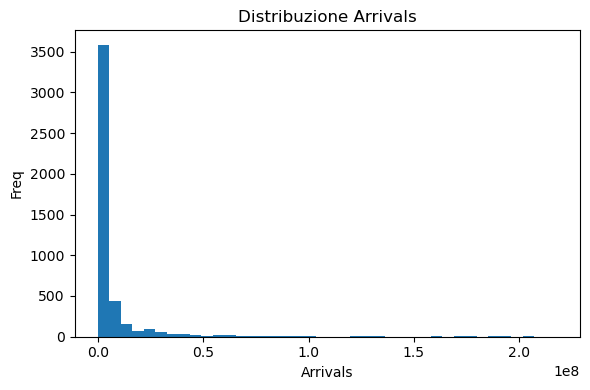

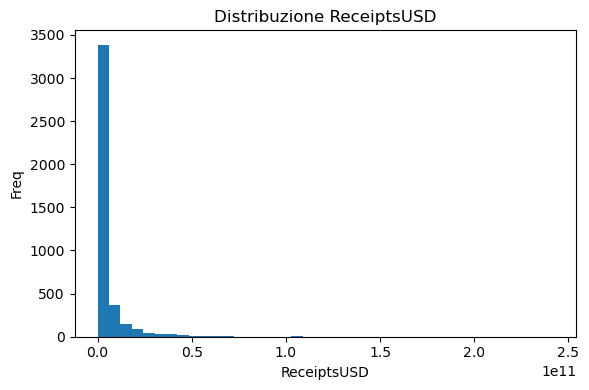

In [34]:
def plot_hist(df: pd.DataFrame, column: str, bins: int = 30) -> None:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(df[column].dropna(), bins=bins)
    ax.set_title(f"Distribuzione {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Freq")
    plt.tight_layout()
    plt.show()

plot_hist(df_countries, "Arrivals", bins=40)
plot_hist(df_countries, "ReceiptsUSD", bins=40)


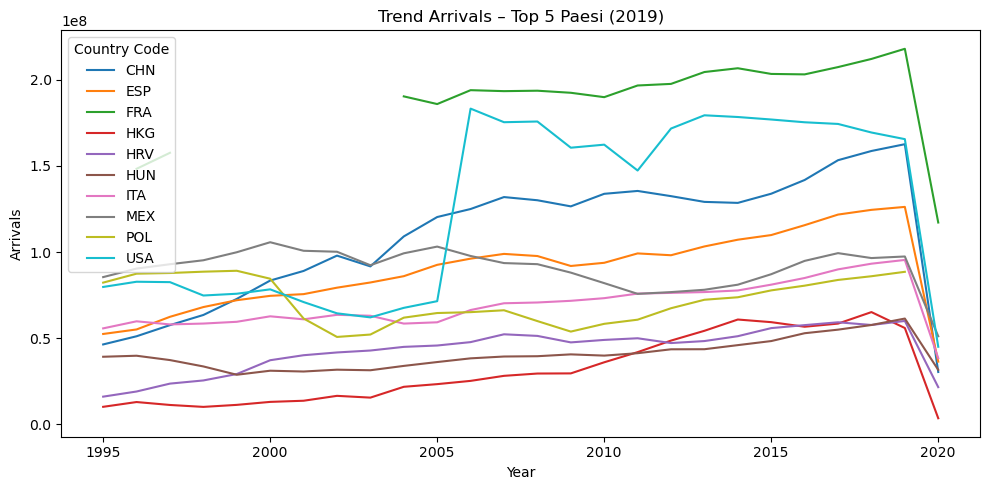

In [47]:
year_ref = 2019
top10 = (df_countries[df_countries["Year"] == year_ref]
        .nlargest(10, "Arrivals")["Country Code"])

trend = df_countries[df_countries["Country Code"].isin(top10)]

plt.figure(figsize=(10, 5))
for cc, grp in trend.groupby("Country Code"):
    plt.plot(grp["Year"], grp["Arrivals"], label=cc)

plt.title(f"Trend Arrivals – Top 5 Paesi ({year_ref})")
plt.xlabel("Year")
plt.ylabel("Arrivals")
plt.legend(title="Country Code")
plt.tight_layout()
plt.show()


# Dati dal 2005

In [63]:
df_countries_last_years = df_countries[
    df_countries["Year"].between(2005, 2019)   # 2005 ≤ Year ≤ 2019
]

In [64]:
# 1) Rimuovo l’indice dal DataFrame definitivo
df_countries_last_years.reset_index(drop=True, inplace=True)

# 2) Esporto in CSV senza indice
df_countries_last_years.to_csv("tourism_2005_2019.csv", index=False)

In [65]:
df_countries_last_years

,Country Name,Country Code,Year,Arrivals,Departures,ReceiptsUSD,ReceiptsEXP,TrnR,TrnX,TvlR,SpendUSD,SpendEXP
0,Aruba,ABW,2005,1286000.0,NaN,1.097000e+09,19.164862,NaN,24000000.0,1.097000e+09,250000000.0,4.992106
1,Aruba,ABW,2006,1285000.0,NaN,1.064100e+09,17.657710,1.000000e+05,23000000.0,1.064000e+09,241000000.0,4.398185
2,Aruba,ABW,2007,1254000.0,NaN,1.213400e+09,18.170598,4.000000e+05,19000000.0,1.213000e+09,270000000.0,4.567405
3,Aruba,ABW,2008,1383000.0,NaN,1.352000e+09,19.151051,1.000000e+06,22000000.0,1.351000e+09,272000000.0,3.993013
4,Aruba,ABW,2009,1420000.0,NaN,1.223000e+09,35.041858,1.000000e+06,21000000.0,1.222000e+09,264000000.0,8.392264
...,...,...,...,...,...,...,...,...,...,...,...,...
3026,Zimbabwe,ZWE,2015,2057000.0,3393000.0,1.910000e+08,4.818169,1.600000e+07,81000000.0,1.750000e+08,557000000.0,7.720269
3027,Zimbabwe,ZWE,2016,2168000.0,3192000.0,1.940000e+08,4.778703,1.700000e+07,79000000.0,1.770000e+08,406000000.0,6.559708
3028,Zimbabwe,ZWE,2017,2423000.0,2768000.0,1.580000e+08,3.405013,9.000000e+06,22000000.0,1.490000e+08,337000000.0,5.416872
3029,Zimbabwe,ZWE,2018,2580000.0,2288000.0,1.910000e+08,3.688565,9.000000e+06,21000000.0,1.820000e+08,269000000.0,3.519928


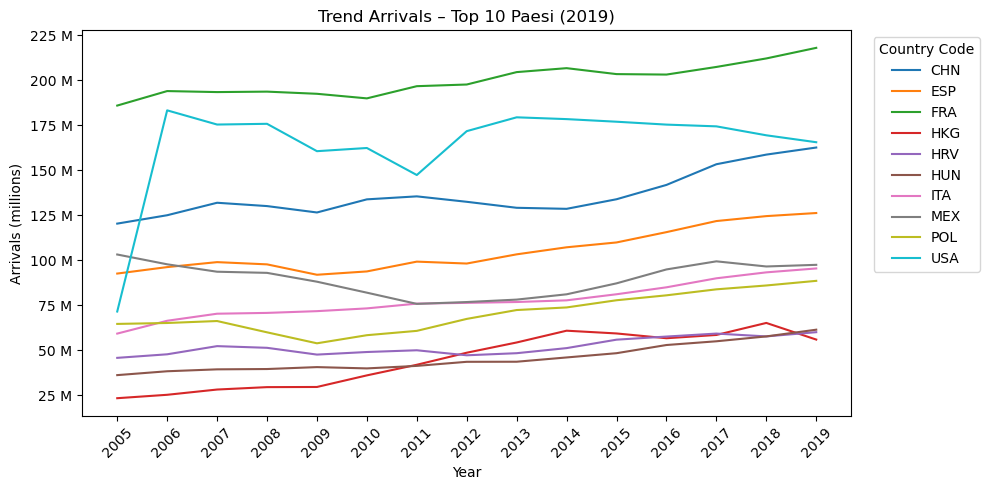

In [60]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

year_ref = 2019
top10 = (df_countries_last_years[df_countries_last_years["Year"] == year_ref]
         .nlargest(10, "Arrivals")["Country Code"])

trend = df_countries_last_years[df_countries_last_years["Country Code"].isin(top10)]

fig, ax = plt.subplots(figsize=(10, 5))

# ── 1. Traccia le linee, convertendo gli arrivi in milioni ───────────
for cc, grp in trend.groupby("Country Code"):
    ax.plot(grp["Year"], grp["Arrivals"] / 1_000_000, label=cc)   # ÷1e6

# ── 2. Tick dell’asse X anno-per-anno ────────────────────────────────
years = sorted(trend["Year"].unique())        # es. 2005–2019
ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45)

# ── 3. Formatter asse Y: “n M” (milioni) ─────────────────────────────
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.0f M'))

# ── 4. Titoli & layout ───────────────────────────────────────────────
ax.set_title(f"Trend Arrivals – Top 10 Paesi ({year_ref})")
ax.set_xlabel("Year")
ax.set_ylabel("Arrivals (millions)")
ax.legend(title="Country Code", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
